Shape: (731, 16) 

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB

None

Head: 
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0

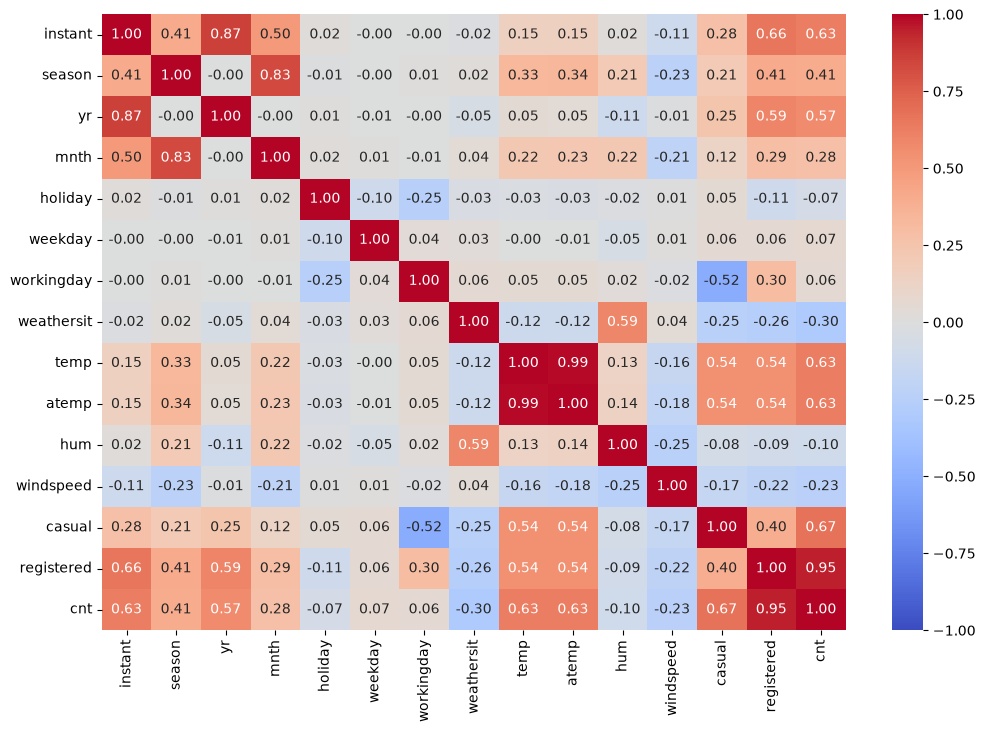

In [1]:
from config import PATH
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

df_day = pd.read_csv(PATH)
print(f"Shape: {df_day.shape} \n")   
print(f"\n{df_day.info()}")
print(f"\nHead: \n{df_day.head()}")
print(f"\nDescribe: \n{df_day.describe()}")
print(f"\nDuplicated: \n{df_day.duplicated().sum()}")

corr_matrix = df_day.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.show()


In [ ]:
#ДС day имеется 16 признаков, 731 строка, дубликатов нет, пропущенных значений нет, отрицательных значений нет. Признаки имеют в основном числовой (int, float) тип данных, кроме dteday. 
#Признаки install (Порядковый номер дня), dteday (Дата) не несут полезной информации, т.к. они не влияют на целевую переменную (поскольку есть такие переменные, как season, yr,weekday, mnth, holiday, workingdat)
#Признак yr может быть полезен для анализа, т.к. может отражать изменение в популярности компании, притоку клиентов.
#По тепловой карте видно, что признаки mnth и season, atemp и temp сильно коррелируют (думаю стоит отсавить atemp поскольку люди арендуют велосипеды и ориетируются на то как они чувствуют погоду)
#Необходимо удалить признаки casual и registered Причина: cnt = casual + registered
#Целевая переменаая cnt

count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64


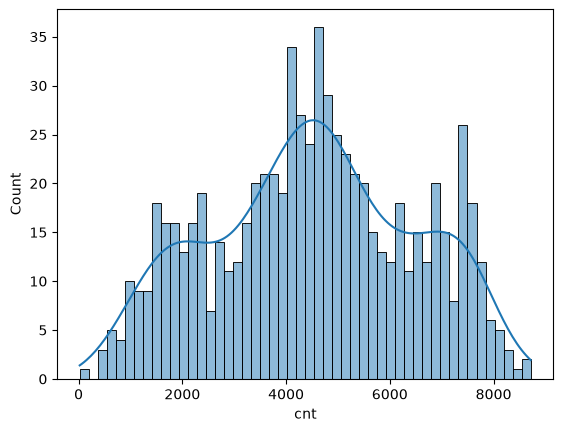

In [3]:
#Исследование переменной cnt

print(df_day["cnt"].describe())

sns.histplot(
    data=df_day,
    x="cnt",
    bins=50,
    kde=True
)

plt.show()

In [4]:
#На графике видно, что распределение переменной нормальное. Особых выбросов нет.